In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/playground-series-s4e9/sample_submission.csv
/kaggle/input/playground-series-s4e9/train.csv
/kaggle/input/playground-series-s4e9/test.csv


In [2]:
# Basic & EDA
import numpy as np
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import warnings
warnings.filterwarnings('ignore')

# Modeling
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.metrics import matthews_corrcoef
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import classification_report
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import KNNImputer
from sklearn.model_selection import StratifiedKFold

# Model library
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from catboost import CatBoostRegressor, Pool
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LinearRegression

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
train_df = pd.read_csv("/kaggle/input/playground-series-s4e9/train.csv")
test_df = pd.read_csv("/kaggle/input/playground-series-s4e9/test.csv")
sample_df = pd.read_csv("/kaggle/input/playground-series-s4e9/sample_submission.csv")

In [5]:
print("Duplicates in train_df:", train_df.duplicated().sum())
print("Duplicates in test_df:", test_df.duplicated().sum())
print("Duplicates in sample_df:", sample_df.duplicated().sum())

Duplicates in train_df: 0
Duplicates in test_df: 0
Duplicates in sample_df: 0


In [6]:
pd.options.display.max_columns = None
print('Tail 10 Examples of Train Dataset : ')
train_df.tail(10)

Tail 10 Examples of Train Dataset : 


,id,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
188523,188523,BMW,328 i,2011,239000,Gasoline,230.0HP 3.0L Straight 6 Cylinder Engine Gasoli...,6-Speed A/T,Black,Black,None reported,Yes,8000
188524,188524,Chevrolet,Camaro 1LT,2019,59692,Gasoline,335.0HP 3.6L V6 Cylinder Engine Gasoline Fuel,10-Speed A/T,Red,Black,At least 1 accident or damage reported,Yes,33600
188525,188525,Audi,A4 2.0T Premium quattro,2011,121886,Gasoline,211.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,8-Speed A/T,Gray,Black,None reported,Yes,6000
188526,188526,GMC,Yukon XL Denali,2016,89291,Gasoline,420.0HP 6.2L 8 Cylinder Engine Gasoline Fuel,8-Speed A/T,Red,Black,At least 1 accident or damage reported,Yes,24700
188527,188527,Chevrolet,Camaro Z28,1999,110000,Gasoline,310.0HP 5.7L 8 Cylinder Engine Gasoline Fuel,A/T,White,Gray,None reported,Yes,14500
188528,188528,Cadillac,Escalade ESV Platinum,2017,49000,Gasoline,420.0HP 6.2L 8 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,White,Beige,None reported,Yes,27500
188529,188529,Mercedes-Benz,AMG C 43 AMG C 43 4MATIC,2018,28600,Gasoline,385.0HP 3.0L V6 Cylinder Engine Gasoline Fuel,8-Speed A/T,White,Black,At least 1 accident or damage reported,Yes,30000
188530,188530,Mercedes-Benz,AMG GLC 63 Base 4MATIC,2021,13650,Gasoline,469.0HP 4.0L 8 Cylinder Engine Gasoline Fuel,7-Speed A/T,White,Black,None reported,Yes,86900
188531,188531,Audi,S5 3.0T Prestige,2022,13895,Gasoline,3.0L,1-Speed Automatic,Daytona Gray Pearl Effect,Black,None reported,NaN,84900
188532,188532,Porsche,Macan Base,2016,59500,Gasoline,252.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,White,Black,None reported,Yes,28995


In [7]:
train_df.head()

,id,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,0,MINI,Cooper S Base,2007,213000,Gasoline,172.0HP 1.6L 4 Cylinder Engine Gasoline Fuel,A/T,Yellow,Gray,None reported,Yes,4200
1,1,Lincoln,LS V8,2002,143250,Gasoline,252.0HP 3.9L 8 Cylinder Engine Gasoline Fuel,A/T,Silver,Beige,At least 1 accident or damage reported,Yes,4999
2,2,Chevrolet,Silverado 2500 LT,2002,136731,E85 Flex Fuel,320.0HP 5.3L 8 Cylinder Engine Flex Fuel Capab...,A/T,Blue,Gray,None reported,Yes,13900
3,3,Genesis,G90 5.0 Ultimate,2017,19500,Gasoline,420.0HP 5.0L 8 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,Black,Black,None reported,Yes,45000
4,4,Mercedes-Benz,Metris Base,2021,7388,Gasoline,208.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,7-Speed A/T,Black,Beige,None reported,Yes,97500


In [8]:
print('The shape of train dataset is', train_df.shape)
print('The shape of test dataset is', test_df.shape)

The shape of train dataset is (188533, 13)
The shape of test dataset is (125690, 12)


In [9]:
print('The duplicate rows in the train dataset :', train_df.duplicated().sum() )
print('The duplicate rows in the test dataset :', test_df.duplicated().sum() )

The duplicate rows in the train dataset : 0
The duplicate rows in the test dataset : 0


In [10]:
print('The Descriptive Statistics of Train Data : \n')
train_df.describe().T

The Descriptive Statistics of Train Data : 



,count,mean,std,min,25%,50%,75%,max
id,188533.0,94266.000000,54424.933488,0.0,47133.0,94266.0,141399.0,188532.0
model_year,188533.0,2015.829998,5.660967,1974.0,2013.0,2017.0,2020.0,2024.0
milage,188533.0,65705.295174,49798.158076,100.0,24115.0,57785.0,95400.0,405000.0
price,188533.0,43878.016178,78819.522254,2000.0,17000.0,30825.0,49900.0,2954083.0


In [11]:
print('The Descriptive Statistics of Test Data : \n')
test_df.describe().T

The Descriptive Statistics of Test Data : 



,count,mean,std,min,25%,50%,75%,max
id,125690.0,251377.500000,36283.722005,188533.0,219955.25,251377.5,282799.75,314222.0
model_year,125690.0,2015.797526,5.673797,1974.0,2013.00,2017.0,2020.00,2024.0
milage,125690.0,66042.581510,50223.858435,100.0,24500.00,57500.0,95798.00,405000.0


In [12]:
print('The data type of each columns of train dataset : \n')
train_df.info()

The data type of each columns of train dataset : 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 188533 entries, 0 to 188532
Data columns (total 13 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   id            188533 non-null  int64 
 1   brand         188533 non-null  object
 2   model         188533 non-null  object
 3   model_year    188533 non-null  int64 
 4   milage        188533 non-null  int64 
 5   fuel_type     183450 non-null  object
 6   engine        188533 non-null  object
 7   transmission  188533 non-null  object
 8   ext_col       188533 non-null  object
 9   int_col       188533 non-null  object
 10  accident      186081 non-null  object
 11  clean_title   167114 non-null  object
 12  price         188533 non-null  int64 
dtypes: int64(4), object(9)
memory usage: 18.7+ MB


In [13]:
features = ['brand', 'model', 'model_year', 'milage', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title', 'price']
num_f = ['model_year', 'milage']
cat_f = ['clean_title', 'accident', 'model', 'transmission', 'engine', 'ext_col', 'fuel_type', 'int_col', 'brand']

print('features :', features)
print('num_features :', num_f)
print('cat_features :', cat_f)

features : ['brand', 'model', 'model_year', 'milage', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title', 'price']
num_features : ['model_year', 'milage']
cat_features : ['clean_title', 'accident', 'model', 'transmission', 'engine', 'ext_col', 'fuel_type', 'int_col', 'brand']


In [14]:
print('The missing valuse of train dataset : \n', train_df.isnull().sum())
print('The missing valuse of test dataset : \n' , test_df.isnull().sum())

The missing valuse of train dataset : 
 id                  0
brand               0
model               0
model_year          0
milage              0
fuel_type        5083
engine              0
transmission        0
ext_col             0
int_col             0
accident         2452
clean_title     21419
price               0
dtype: int64
The missing valuse of test dataset : 
 id                  0
brand               0
model               0
model_year          0
milage              0
fuel_type        3383
engine              0
transmission        0
ext_col             0
int_col             0
accident         1632
clean_title     14239
dtype: int64


In [15]:
train_df.columns

Index(['id', 'brand', 'model', 'model_year', 'milage', 'fuel_type', 'engine',
       'transmission', 'ext_col', 'int_col', 'accident', 'clean_title',
       'price'],
      dtype='object')

In [16]:
train_df['brand'].unique()

array(['MINI', 'Lincoln', 'Chevrolet', 'Genesis', 'Mercedes-Benz', 'Audi',
       'Ford', 'BMW', 'Tesla', 'Cadillac', 'Land', 'GMC', 'Toyota',
       'Hyundai', 'Volvo', 'Volkswagen', 'Buick', 'Rivian', 'RAM',
       'Hummer', 'Alfa', 'INFINITI', 'Jeep', 'Porsche', 'McLaren',
       'Honda', 'Lexus', 'Dodge', 'Nissan', 'Jaguar', 'Acura', 'Kia',
       'Mitsubishi', 'Rolls-Royce', 'Maserati', 'Pontiac', 'Saturn',
       'Bentley', 'Mazda', 'Subaru', 'Ferrari', 'Aston', 'Lamborghini',
       'Chrysler', 'Lucid', 'Lotus', 'Scion', 'smart', 'Karma',
       'Plymouth', 'Suzuki', 'FIAT', 'Saab', 'Bugatti', 'Mercury',
       'Polestar', 'Maybach'], dtype=object)

In [17]:
len(train_df['transmission'].unique())

52

In [18]:
train_df.groupby('model_year').size()

model_year
1974       12
1992       14
1993      140
1994       92
1995      102
1996      189
1997      312
1998      343
1999      554
2000      558
2001     1534
2002     1282
2003     1906
2004     2570
2005     3129
2006     2814
2007     4876
2008     5156
2009     2716
2010     4235
2011     6265
2012     6095
2013     6796
2014     8415
2015    11389
2016    13696
2017    12794
2018    16414
2019    15409
2020    15848
2021    18198
2022    15749
2023     8769
2024      162
dtype: int64

In [19]:
import pandas as pd
import re

# Sample DataFrame
data = train_df

train_df = pd.DataFrame(data)

# Define regex patterns
hp_pattern = r'(\d+\.?\d*)HP'
size_pattern = r'(\d+\.?\d*)L'
type_pattern = r'(\d+ Cylinder Engine)'

# Extract features
train_df['horsepower'] = train_df['engine'].apply(lambda x: float(re.search(hp_pattern, x).group(1)) if re.search(hp_pattern, x) else None)
train_df['engine_size'] = train_df['engine'].apply(lambda x: float(re.search(size_pattern, x).group(1)) if re.search(size_pattern, x) else None)
train_df['engine_type'] = train_df['engine'].apply(lambda x: re.search(type_pattern, x).group(1) if re.search(type_pattern, x) else None)

# Drop the original 'engine' column if no longer needed
train_df.drop(columns=['engine'], inplace=True)

print(train_df)


            id          brand                     model  model_year  milage  \
0            0           MINI             Cooper S Base        2007  213000   
1            1        Lincoln                     LS V8        2002  143250   
2            2      Chevrolet         Silverado 2500 LT        2002  136731   
3            3        Genesis          G90 5.0 Ultimate        2017   19500   
4            4  Mercedes-Benz               Metris Base        2021    7388   
...        ...            ...                       ...         ...     ...   
188528  188528       Cadillac     Escalade ESV Platinum        2017   49000   
188529  188529  Mercedes-Benz  AMG C 43 AMG C 43 4MATIC        2018   28600   
188530  188530  Mercedes-Benz    AMG GLC 63 Base 4MATIC        2021   13650   
188531  188531           Audi          S5 3.0T Prestige        2022   13895   
188532  188532        Porsche                Macan Base        2016   59500   

            fuel_type                    transmissi

In [20]:
train_df.head()

,id,brand,model,model_year,milage,fuel_type,transmission,ext_col,int_col,accident,clean_title,price,horsepower,engine_size,engine_type
0,0,MINI,Cooper S Base,2007,213000,Gasoline,A/T,Yellow,Gray,None reported,Yes,4200,172.0,1.6,4 Cylinder Engine
1,1,Lincoln,LS V8,2002,143250,Gasoline,A/T,Silver,Beige,At least 1 accident or damage reported,Yes,4999,252.0,3.9,8 Cylinder Engine
2,2,Chevrolet,Silverado 2500 LT,2002,136731,E85 Flex Fuel,A/T,Blue,Gray,None reported,Yes,13900,320.0,5.3,8 Cylinder Engine
3,3,Genesis,G90 5.0 Ultimate,2017,19500,Gasoline,Transmission w/Dual Shift Mode,Black,Black,None reported,Yes,45000,420.0,5.0,8 Cylinder Engine
4,4,Mercedes-Benz,Metris Base,2021,7388,Gasoline,7-Speed A/T,Black,Beige,None reported,Yes,97500,208.0,2.0,4 Cylinder Engine


In [21]:
import pandas as pd
import re

# Sample DataFrame
data = test_df

test_df = pd.DataFrame(data)

# Define regex patterns
hp_pattern = r'(\d+\.?\d*)HP'
size_pattern = r'(\d+\.?\d*)L'
type_pattern = r'(\d+ Cylinder Engine)'

# Extract features
test_df['horsepower'] = test_df['engine'].apply(lambda x: float(re.search(hp_pattern, x).group(1)) if re.search(hp_pattern, x) else None)
test_df['engine_size'] = test_df['engine'].apply(lambda x: float(re.search(size_pattern, x).group(1)) if re.search(size_pattern, x) else None)
test_df['engine_type'] = test_df['engine'].apply(lambda x: re.search(type_pattern, x).group(1) if re.search(type_pattern, x) else None)

# Drop the original 'engine' column if no longer needed
test_df.drop(columns=['engine'], inplace=True)

print(test_df)


            id          brand                   model  model_year  milage  \
0       188533           Land          Rover LR2 Base        2015   98000   
1       188534           Land       Rover Defender SE        2020    9142   
2       188535           Ford      Expedition Limited        2022   28121   
3       188536           Audi           A6 2.0T Sport        2016   61258   
4       188537           Audi    A6 2.0T Premium Plus        2018   59000   
...        ...            ...                     ...         ...     ...   
125685  314218  Mercedes-Benz  GL-Class GL 450 4MATIC        2014   83315   
125686  314219           Audi          Q7 55 Prestige        2019   29336   
125687  314220           Audi    A6 3.0T Premium Plus        2012   77634   
125688  314221           Audi         Q7 3.0T Premium        2012  112000   
125689  314222      Chevrolet                Tahoe LT        2018   66840   

       fuel_type        transmission          ext_col int_col       acciden

In [22]:
test_df.head()

,id,brand,model,model_year,milage,fuel_type,transmission,ext_col,int_col,accident,clean_title,horsepower,engine_size,engine_type
0,188533,Land,Rover LR2 Base,2015,98000,Gasoline,6-Speed A/T,White,Beige,None reported,Yes,240.0,2.0,4 Cylinder Engine
1,188534,Land,Rover Defender SE,2020,9142,Hybrid,8-Speed A/T,Silver,Black,None reported,Yes,395.0,3.0,6 Cylinder Engine
2,188535,Ford,Expedition Limited,2022,28121,Gasoline,10-Speed Automatic,White,Ebony,None reported,NaN,NaN,3.5,None
3,188536,Audi,A6 2.0T Sport,2016,61258,Gasoline,Automatic,Silician Yellow,Black,None reported,NaN,NaN,NaN,None
4,188537,Audi,A6 2.0T Premium Plus,2018,59000,Gasoline,A/T,Gray,Black,None reported,Yes,252.0,2.0,4 Cylinder Engine


In [23]:
train_df['fuel_type'].unique()

array(['Gasoline', 'E85 Flex Fuel', nan, 'Hybrid', 'Diesel',
       'Plug-In Hybrid', '–', 'not supported'], dtype=object)

In [24]:
train_df.isna().sum()

id                  0
brand               0
model               0
model_year          0
milage              0
fuel_type        5083
transmission        0
ext_col             0
int_col             0
accident         2452
clean_title     21419
price               0
horsepower      33259
engine_size     14214
engine_type     37908
dtype: int64

In [25]:
train_df.describe()

,id,model_year,milage,price,horsepower,engine_size
count,188533.000000,188533.000000,188533.000000,1.885330e+05,155274.000000,174319.000000
mean,94266.000000,2015.829998,65705.295174,4.387802e+04,343.263856,3.806676
std,54424.933488,5.660967,49798.158076,7.881952e+04,114.734210,1.355945
min,0.000000,1974.000000,100.000000,2.000000e+03,70.000000,0.650000
25%,47133.000000,2013.000000,24115.000000,1.700000e+04,263.000000,3.000000
50%,94266.000000,2017.000000,57785.000000,3.082500e+04,329.000000,3.500000
75%,141399.000000,2020.000000,95400.000000,4.990000e+04,416.000000,4.800000
max,188532.000000,2024.000000,405000.000000,2.954083e+06,1020.000000,8.400000


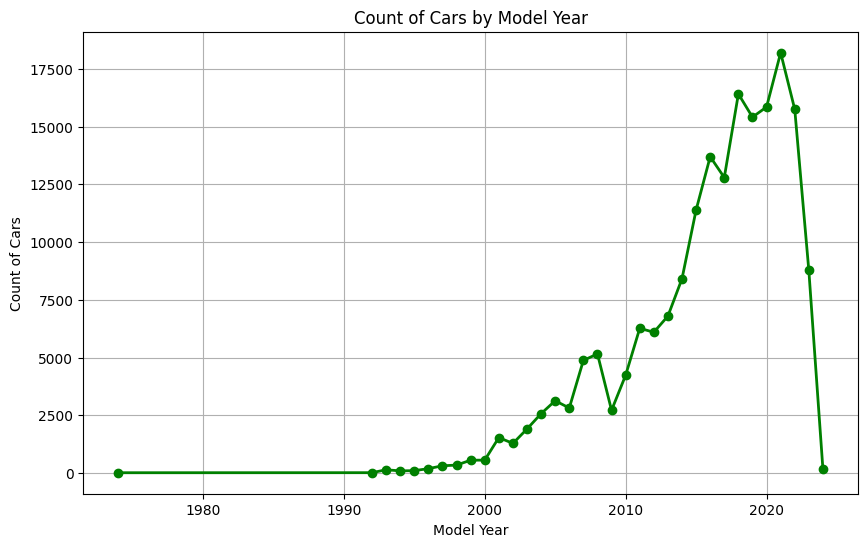

In [26]:
import matplotlib.pyplot as plt

# Group by 'model_year' and get the count
model_year_count = train_df.groupby('model_year').size().reset_index(name='count')

# Plotting the line graph for count by model_year
plt.figure(figsize=(10, 6))
plt.plot(model_year_count['model_year'], model_year_count['count'], marker='o', color='g', linestyle='-', linewidth=2)

# Adding labels and title
plt.xlabel('Model Year')
plt.ylabel('Count of Cars')
plt.title('Count of Cars by Model Year')
plt.grid(True)

# Show the plot
plt.show()


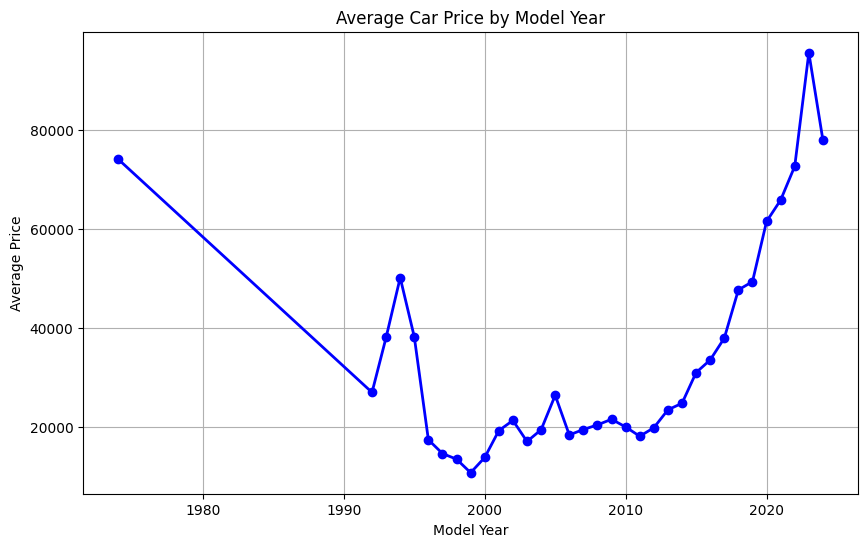

In [27]:
import matplotlib.pyplot as plt
import pandas as pd

# Assuming your training dataframe is 'train_df'
# Group by 'model_year' and calculate the mean price for each year
model_year_price = train_df.groupby('model_year')['price'].mean().reset_index()

# Plotting the line graph
plt.figure(figsize=(10, 6))
plt.plot(model_year_price['model_year'], model_year_price['price'], marker='o', color='b', linestyle='-', linewidth=2)

# Adding labels and title
plt.xlabel('Model Year')
plt.ylabel('Average Price')
plt.title('Average Car Price by Model Year')
plt.grid(True)

# Show the plot
plt.show()

## Preprocessing

In [28]:
def cleaning_data(df):

    fuel_type_imputer = SimpleImputer(strategy='most_frequent')
    df['fuel_type'] = fuel_type_imputer.fit_transform(df[['fuel_type']]).ravel() 
    
    missing_label_imputer = SimpleImputer(strategy='constant', fill_value='missing')
    df[['accident', 'clean_title']] = missing_label_imputer.fit_transform(df[['accident', 'clean_title']])
    
    return df

In [29]:
train_df_cleaned = cleaning_data(train_df)
print('The missing valuse of train dataset after handling missing values : \n', train_df_cleaned.isnull().sum())

The missing valuse of train dataset after handling missing values : 
 id                  0
brand               0
model               0
model_year          0
milage              0
fuel_type           0
transmission        0
ext_col             0
int_col             0
accident            0
clean_title         0
price               0
horsepower      33259
engine_size     14214
engine_type     37908
dtype: int64


In [30]:
from sklearn.model_selection import train_test_split
x_train = train_df[['model_year', 'milage', 'brand', 'fuel_type', 'clean_title', 'accident', 'horsepower', 'engine_size', 'engine_type']]
y_train = train_df['price']
test = test_df[['model_year', 'milage', 'brand', 'fuel_type', 'clean_title', 'accident', 'horsepower', 'engine_size', 'engine_type']]

X_train_exp, X_test_exp, y_train, y_test = train_test_split(x_train, y_train, test_size=0.2, random_state=42)

X_train_exp.shape, X_test_exp.shape, test.shape, y_train.shape, y_test.shape

((150826, 9), (37707, 9), (125690, 9), (150826,), (37707,))

In [31]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.impute import SimpleImputer

# Scalers and Imputers
ss = StandardScaler(with_mean=False, with_std=True)
rr = RobustScaler()
si2 = SimpleImputer()
si3 = SimpleImputer()

# One-Hot Encoder for categorical features
one_hot = OneHotEncoder(handle_unknown='ignore')

# Pipelines for numerical features
milage_pipeline = Pipeline([('num1', si2), ('scale', ss)])
model_pipeline = Pipeline([('num2', si3), ('scale', ss)])
horsepower_pipeline = Pipeline([('num3', si3), ('scale', ss)])
engine_size_pipeline = Pipeline([('num4', si3), ('scale', ss)])

# Preprocessing pipeline for categorical features
cat_pipeline = Pipeline([('impute', SimpleImputer(strategy='most_frequent')), 
                         ('onehot', one_hot)])

# Combine numerical and categorical transformers
pre1 = ColumnTransformer([
    ('milage', milage_pipeline, ['milage']),
    ('model_year', model_pipeline, ['model_year']),
    ('horsepower', horsepower_pipeline, ['horsepower']),
    ('engine_size', engine_size_pipeline, ['engine_size']),
    ('engine_type', cat_pipeline, ['engine_type']),
    ('brand', cat_pipeline, ['brand']),
    ('fuel_type', cat_pipeline, ['fuel_type']),
    ('clean_title', cat_pipeline, ['clean_title']),
    ('accident', cat_pipeline, ['accident'])
], verbose_feature_names_out=False)

# Combine all preprocessors using FeatureUnion (if needed)
preprocessor = pre1

# Transform training and testing data
X_train_enc = preprocessor.fit_transform(X_train_exp)
X_test_enc = preprocessor.transform(X_test_exp)
test_enc = preprocessor.transform(test)

# Optionally, print the shape of transformed data to verify
print("X_train_enc shape:", X_train_enc.shape)
print("X_test_enc shape:", X_test_enc.shape)
print("test_enc shape:", test_enc.shape)


X_train_enc shape: (150826, 81)
X_test_enc shape: (37707, 81)
test_enc shape: (125690, 81)


In [32]:
import xgboost as xgb
from sklearn.metrics import mean_squared_error
import numpy as np

# Apply the preprocessing pipeline to encode and scale the data
X_train_enc = preprocessor.fit_transform(X_train_exp)
X_test_enc = preprocessor.transform(X_test_exp)
test_enc = preprocessor.transform(test)

# Create the DMatrix for XGBoost
dtrain_xgb = xgb.DMatrix(X_train_enc, label=y_train)
dtest_xgb = xgb.DMatrix(X_test_enc)
dtest_final_xgb = xgb.DMatrix(test_enc)

# Set XGBoost parameters
params = {
    'objective': 'reg:squarederror',  # Correct objective for regression
    'eval_metric': 'rmse',
    'max_depth': 11,
    'eta': 0.01,
    'random_state': 42
}

# Train the model
xgb_model = xgb.train(params, dtrain_xgb, num_boost_round=100)

# Predict prices for the test set
y_pred_xgb = xgb_model.predict(dtest_xgb)

# Predict prices for the final test data
test_pred_xgb = xgb_model.predict(dtest_final_xgb)

# Print predictions (optional)
print("Predicted prices for the test data:", y_pred_xgb[:5])
print("Predicted prices for the final test data:", test_pred_xgb[:5])

# Assuming y_test is available
# Calculate Mean Squared Error and Root Mean Squared Error on validation set
mse = mean_squared_error(y_test, y_pred_xgb)
rmse = np.sqrt(mse)
print(f"XGBoost Mean Squared Error: {mse}")
print(f"XGBoost Root Mean Squared Error (RMSE): {rmse}")


Predicted prices for the test data: [50108.277 29439.574 38805.324 31654.906 38765.055]
Predicted prices for the final test data: [27320.938 65625.53  51043.41  36558.47  35444.777]
XGBoost Mean Squared Error: 4878918979.03298
XGBoost Root Mean Squared Error (RMSE): 69849.25897268331


In [33]:
from catboost import CatBoostRegressor
from sklearn.metrics import mean_squared_error
import numpy as np

# Apply the preprocessing pipeline to encode and scale the data
X_train_enc = preprocessor.fit_transform(X_train_exp)
X_test_enc = preprocessor.transform(X_test_exp)
test_enc = preprocessor.transform(test)

# Initialize the CatBoost regressor
cat_model = CatBoostRegressor(
    iterations=1000,        # Number of boosting rounds
    learning_rate=0.01,     # Learning rate
    depth=11,               # Maximum tree depth
    eval_metric='RMSE',     # Metric for evaluation
    random_seed=42,
    early_stopping_rounds=10,
    verbose=100             # Verbosity for training updates
)

# Train the model
cat_model.fit(X_train_enc, y_train, eval_set=(X_test_enc, y_test), use_best_model=True)

# Predict prices for the test set
y_pred = cat_model.predict(X_test_enc)

# Calculate Mean Squared Error
mse = mean_squared_error(y_test, y_pred)
print(f"Mean Squared Error: {mse}")

# Calculate Root Mean Squared Error (RMSE)
rmse = np.sqrt(mse)
print(f"Root Mean Squared Error (RMSE): {rmse}")

# Predict prices for the final test data
test_pred = cat_model.predict(test_enc)

# Optionally, print the first few predictions for the test data
print("Predicted prices for the test data:", test_pred[:5])


0:	learn: 79744.0602933	test: 74467.0795717	best: 74467.0795717 (0)	total: 117ms	remaining: 1m 56s
100:	learn: 74628.1613766	test: 69451.9797977	best: 69451.9797977 (100)	total: 4.48s	remaining: 39.9s
200:	learn: 73236.9820416	test: 68505.0196210	best: 68505.0196210 (200)	total: 8.74s	remaining: 34.8s
300:	learn: 72560.2734627	test: 68299.5865776	best: 68299.5865776 (300)	total: 13.1s	remaining: 30.4s
400:	learn: 72070.5391626	test: 68229.7757940	best: 68229.7757940 (400)	total: 17.7s	remaining: 26.5s
Stopped by overfitting detector  (10 iterations wait)

bestTest = 68226.61182
bestIteration = 413

Shrink model to first 414 iterations.
Mean Squared Error: 4654870560.454805
Root Mean Squared Error (RMSE): 68226.61182013075
Predicted prices for the test data: [17183.04449812 75657.44141433 54511.00812854 31251.84102383
 29539.09026856]


In [34]:
import lightgbm as lgb
from sklearn.metrics import mean_squared_error
import numpy as np

# Apply the preprocessing pipeline to encode and scale the data
X_train_enc = preprocessor.fit_transform(X_train_exp)
X_test_enc = preprocessor.transform(X_test_exp)
test_enc = preprocessor.transform(test)

# Create the LightGBM dataset
dtrain = lgb.Dataset(X_train_enc, label=y_train)
dtest = lgb.Dataset(X_test_enc, label=y_test, reference=dtrain)

# Set LightGBM parameters with L2 regularization
params = {
    'objective': 'regression',
    'metric': 'rmse',
    'boosting_type': 'gbdt',
    'max_depth': 6,
    'num_leaves': 31,
    'learning_rate': 0.05,
    'lambda_l2': 2.0,  # Apply L2 regularization with a regularization strength of 1.0
    'random_state': 42
}

# Train the LightGBM model
lgb_model = lgb.train(params, dtrain, valid_sets=[dtrain, dtest], num_boost_round=200)

# Predict prices for the test set
y_pred = lgb_model.predict(X_test_enc)

# Calculate Mean Squared Error
mse = mean_squared_error(y_test, y_pred)
print(f"Mean Squared Error: {mse}")

# Calculate Root Mean Squared Error (RMSE)
rmse = np.sqrt(mse)
print(f"Root Mean Squared Error (RMSE): {rmse}")

# Predict prices for the final test data
test_pred = lgb_model.predict(test_enc)

# Optionally, print the first few predictions for the test data
print("Predicted prices for the test data:", test_pred[:5])


[LightGBM] [Warning] Accuracy may be bad since you didn't explicitly set num_leaves OR 2^max_depth > num_leaves. (num_leaves=31).
[LightGBM] [Warning] Accuracy may be bad since you didn't explicitly set num_leaves OR 2^max_depth > num_leaves. (num_leaves=31).
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.023382 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 709
[LightGBM] [Info] Number of data points in the train set: 150826, number of used features: 72
[LightGBM] [Warning] Accuracy may be bad since you didn't explicitly set num_leaves OR 2^max_depth > num_leaves. (num_leaves=31).
[LightGBM] [Info] Start training from score 43890.785316
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits 

In [35]:
# import numpy as np
# from sklearn.metrics import mean_squared_error

# # Assuming models are already trained and predictions are obtained

# # Apply the preprocessing pipeline to encode and scale the data
# X_train_enc = preprocessor.fit_transform(X_train_exp)
# X_test_enc = preprocessor.transform(X_test_exp)
# test_enc = preprocessor.transform(test)

# # Initialize and train individual models
# # 1. XGBoost
# dtrain_xgb = xgb.DMatrix(X_train_enc, label=y_train)
# dtest_xgb = xgb.DMatrix(X_test_enc)
# dtest_final_xgb = xgb.DMatrix(test_enc)
# xgb_model = xgb.train(params, dtrain_xgb, num_boost_round=100)
# y_pred_xgb = xgb_model.predict(dtest_xgb)
# test_pred_xgb = xgb_model.predict(dtest_final_xgb)

# # 2. CatBoost
# cat_model = CatBoostRegressor(
#     iterations=1000, learning_rate=0.01, depth=11, eval_metric='RMSE',
#     random_seed=42, early_stopping_rounds=10, verbose=False
# )
# cat_model.fit(X_train_enc, y_train, eval_set=(X_test_enc, y_test), use_best_model=True)
# y_pred_cat = cat_model.predict(X_test_enc)
# test_pred_cat = cat_model.predict(test_enc)

# # 3. LightGBM
# dtrain_lgb = lgb.Dataset(X_train_enc, label=y_train)
# dtest_lgb = lgb.Dataset(X_test_enc, label=y_test, reference=dtrain_lgb)
# params_lgb = {
#     'objective': 'regression', 'metric': 'rmse', 'boosting_type': 'gbdt',
#     'max_depth': 6, 'num_leaves': 31, 'learning_rate': 0.05, 'lambda_l2': 2.0, 
#     'random_state': 42
# }
# lgb_model = lgb.train(params_lgb, dtrain_lgb, valid_sets=[dtrain_lgb, dtest_lgb], num_boost_round=200)
# y_pred_lgb = lgb_model.predict(X_test_enc)
# test_pred_lgb = lgb_model.predict(test_enc)

# # Define the weights (you can adjust these based on model performance)
# weight_xgb = 0.1
# weight_cat = 0.3
# weight_lgb = 0.6

# # Ensemble by weighted averaging
# y_pred_ensemble = (weight_xgb * y_pred_xgb + weight_cat * y_pred_cat + weight_lgb * y_pred_lgb) / (weight_xgb + weight_cat + weight_lgb)
# test_pred_ensemble = (weight_xgb * test_pred_xgb + weight_cat * test_pred_cat + weight_lgb * test_pred_lgb) / (weight_xgb + weight_cat + weight_lgb)

# # Calculate Mean Squared Error and Root Mean Squared Error on validation set
# mse = mean_squared_error(y_test, y_pred_ensemble)
# rmse = np.sqrt(mse)
# print(f"Ensemble Mean Squared Error: {mse}")
# print(f"Ensemble Root Mean Squared Error (RMSE): {rmse}")

# # Optionally, print the first few ensemble predictions for the final test data
# print("Ensemble Predicted prices for the test data:", test_pred_ensemble[:5])


In [36]:
import pandas as pd
submission_df = pd.DataFrame({
    'id': test_df['id'],
    'price': test_pred
})
submission_df.to_csv('submission.csv', index=False)

print("Submission file created successfully!")

Submission file created successfully!


In [37]:
sub = pd.read_csv("submission.csv")

In [38]:
sub.shape

(125690, 2)